In [9]:
!pip install -q imageio[ffmpeg]

import cv2, numpy as np, imageio.v3 as iio

In [23]:
import os, glob, time, gc
import numpy as np
import cv2
import imageio.v3 as iio
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

def find_dataset_root():
    inp = '/kaggle/input'
    for root, dirs, _ in os.walk(inp):
        depth = root[len(inp):].count(os.sep)
        if depth > 4:
            dirs[:] = []
            continue
        if any(os.path.isfile(os.path.join(root, d, 'vid.avi')) for d in dirs):
            return root
    return inp

DATASET_ROOT = find_dataset_root()
OUTPUT_DIR   = '/kaggle/working'
CACHE_DIR = os.path.join(OUTPUT_DIR, 'cache_roi')
CHECKPOINT   = os.path.join(OUTPUT_DIR, 'physnet_lite.pt')
os.makedirs(CACHE_DIR, exist_ok=True)

FACE_SIZE    = 36
CLIP_LEN     = 128
STRIDE       = 64
TEMP_RATIO   = 4
FPS          = 30.0
EPOCHS       = 30
BATCH_SIZE   = 4
LR           = 1e-3
NUM_WORKERS  = 0
VAL_FRAC     = 0.15
TEST_FRAC    = 0.15
SEED         = 42

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [35]:
class DS3DConv(nn.Module):
    def __init__(self, in_ch, out_ch, k, padding=0):
        super().__init__()
        self.dw = nn.Conv3d(in_ch, in_ch, k, padding=padding, groups=in_ch, bias=False)
        self.pw = nn.Conv3d(in_ch, out_ch, 1, bias=False)
        self.bn = nn.BatchNorm3d(out_ch)
    def forward(self, x):
        return F.relu(self.bn(self.pw(self.dw(x))), inplace=True)


class PhysNetLite(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            DS3DConv(3, 16, (1,5,5), padding=(0,2,2)),
            DS3DConv(16, 16, (3,3,3), padding=(1,1,1)),
            nn.AvgPool3d((1,2,2)),
        )
        self.block1 = nn.Sequential(
            DS3DConv(16, 32, (3,3,3), padding=(1,1,1)),
            DS3DConv(32, 32, (3,3,3), padding=(1,1,1)),
            nn.AvgPool3d((2,2,2)),
        )
        self.block2 = nn.Sequential(
            DS3DConv(32, 64, (3,3,3), padding=(1,1,1)),
            DS3DConv(64, 64, (3,3,3), padding=(1,1,1)),
            nn.AvgPool3d((2,2,2)),
        )
        self.block3 = nn.Sequential(
            DS3DConv(64, 64, (3,3,3), padding=(1,1,1)),
            nn.AdaptiveAvgPool3d((None,1,1)),
        )
        self.attn = nn.Sequential(
            nn.Conv1d(64, 16, 1, bias=False), nn.Tanh(),
            nn.Conv1d(16, 64, 1, bias=False), nn.Sigmoid(),
        )
        self.decoder = nn.Sequential(
            nn.Conv1d(64, 32, 3, padding=1, bias=False),
            nn.BatchNorm1d(32),
            nn.ReLU(inplace=True),
            nn.Conv1d(32, 1, 1),
        )
    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x).squeeze(-1).squeeze(-1)
        x = x * self.attn(x)
        return self.decoder(x).squeeze(1)


_m = PhysNetLite()
_n = sum(p.numel() for p in _m.parameters())
with torch.no_grad():
    _y = _m(torch.randn(2,3,128,36,36))
del _m, _y

In [48]:
def bandpass_filter(sig, fps, low=0.7, high=3.5):
    sig = np.asarray(sig, dtype=np.float64)
    n = len(sig)
    if n < 10:
        return sig.astype(np.float32)
    freqs = np.fft.rfftfreq(n, d=1.0/fps)
    spec  = np.fft.rfft(sig)
    mask  = (freqs >= low) & (freqs <= high)
    return np.fft.irfft(spec * mask, n=n).astype(np.float32)

def normalize_signal(sig):
    return (sig - sig.mean()) / (sig.std() + 1e-8)

def crop_center_face(rgb, face_size=FACE_SIZE):
    h, w = rgb.shape[:2]
    side = int(min(h, w) * 0.55)
    cx, cy = w // 2, h // 2
    x1, y1 = cx - side // 2, cy - side // 2
    roi = rgb[y1:y1+side, x1:x1+side]
    return cv2.resize(roi, (face_size, face_size)).astype(np.float32) / 255.0

def signal_to_hr(sig, fps):
    sig = np.asarray(sig, dtype=np.float64)
    n = len(sig)
    freqs = np.fft.rfftfreq(1024, d=1.0/fps)
    spec = np.abs(np.fft.rfft(sig - sig.mean(), n=1024))
    mask = (freqs >= 0.75) & (freqs <= 2.2)
    if not mask.any():
        return 0.0
    peak_freq = freqs[mask][np.argmax(spec[mask])]
    return peak_freq * 60.0

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

class FaceTracker:
    def __init__(self, redetect=10, alpha=0.8):
        self.box, self.i, self.redetect, self.alpha = None, 0, redetect, alpha

    def update(self, rgb):
        if self.i % self.redetect == 0 or self.box is None:
            gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
            faces = face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(80, 80))
            if len(faces):
                new = np.array(max(faces, key=lambda f: f[2]*f[3]), dtype=np.float32)
                self.box = new if self.box is None else self.alpha*self.box + (1-self.alpha)*new
        self.i += 1
        if self.box is None:  # fallback: center box
            h, w = rgb.shape[:2]; s = min(h, w)*0.55
            return np.array([w/2 - s/2, h/2 - s/2, s, s], dtype=np.float32)
        return self.box

def _crop(rgb, x0, y0, x1, y1, size):
    H, W = rgb.shape[:2]
    x0, x1 = int(np.clip(x0, 0, W-2)), int(np.clip(x1, 1, W-1))
    y0, y1 = int(np.clip(y0, 0, H-2)), int(np.clip(y1, 1, H-1))
    if x1 <= x0 or y1 <= y0:
        return np.zeros((size[1], size[0], 3), np.float32)
    return cv2.resize(rgb[y0:y1, x0:x1], size).astype(np.float32) / 255.0

def extract_roi(rgb, box, face_size=FACE_SIZE):
    x, y, w, h = box
    fh = _crop(rgb, x+0.25*w, y+0.02*h, x+0.75*w, y+0.25*h, (face_size, 12))        # forehead
    lc = _crop(rgb, x+0.12*w, y+0.55*h, x+0.40*w, y+0.85*h, (face_size//2, 24))     # left cheek
    rc = _crop(rgb, x+0.60*w, y+0.55*h, x+0.88*w, y+0.85*h, (face_size//2, 24))     # right cheek
    return np.concatenate([fh, np.concatenate([lc, rc], axis=1)], axis=0)           # 36x36x3

In [51]:
!rm -rf /kaggle/working/cache_roi/*

In [52]:
import shutil

MAX_FRAMES_PER_VIDEO = 1800
MAX_SUBJECTS         = 20

DATASET_ROOT = '/kaggle/input/datasets/malekdinarito/ubfc-rppg-dataset'
if not os.path.isdir(DATASET_ROOT):
    for root, dirs, _ in os.walk('/kaggle/input'):
        if root.count('/') > 5: continue
        if any(d.startswith('subject') for d in dirs):
            DATASET_ROOT = root
            break

TMP_VIDEO = '/kaggle/working/_tmp_video.avi'

def load_gt(gt_path, n_frames):
    raw = np.loadtxt(gt_path)
    if raw.ndim > 1:
        raw = raw[0]
    if len(raw) != n_frames:
        idx = np.linspace(0, len(raw)-1, n_frames)
        raw = np.interp(idx, np.arange(len(raw)), raw)
    return raw.astype(np.float32)


def preprocess_subject(subj_dir):
    name = os.path.basename(subj_dir)
    cache_file = os.path.join(CACHE_DIR, f'{name}.npz')
    if os.path.exists(cache_file):
        return

    vid_src = glob.glob(os.path.join(subj_dir, '*.avi'))[0]
    gt_path = glob.glob(os.path.join(subj_dir, '*.txt'))[0]

    shutil.copy(vid_src, TMP_VIDEO)

    tracker = FaceTracker()
    frames = np.zeros((MAX_FRAMES_PER_VIDEO, FACE_SIZE, FACE_SIZE, 3), dtype=np.float32)
    i = 0
    for rgb in iio.imiter(TMP_VIDEO):
        if i >= MAX_FRAMES_PER_VIDEO: break
        frames[i] = extract_roi(rgb, tracker.update(rgb))
        i += 1
    frames = frames[:i]

    cap = cv2.VideoCapture(TMP_VIDEO); n_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); cap.release()
    ppg = load_gt(gt_path, n_total)[:len(frames)]
    np.savez_compressed(cache_file, frames=frames, ppg=ppg)

    os.remove(TMP_VIDEO)
    del frames, ppg
    gc.collect()


subj_dirs = sorted(d for d in glob.glob(os.path.join(DATASET_ROOT, '*')) if os.path.isdir(d))[:MAX_SUBJECTS]

for subj in subj_dirs:
    preprocess_subject(subj)

subjects: 20 | train/val/test clips: 366 81 72


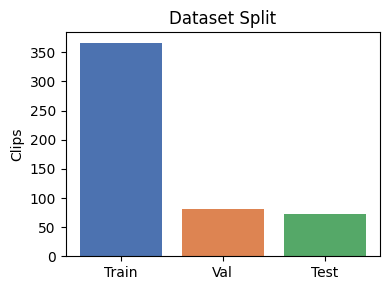

2754

In [53]:
from torch.utils.data import Subset
class UBFCDataset(Dataset):
    def __init__(self, cache_dir, augment=True):
        self.augment = augment
        self.label_len = CLIP_LEN // TEMP_RATIO
        self.clips, self.labels, self.subjects = [], [], []

        cache_files = sorted(glob.glob(os.path.join(cache_dir, '*.npz')))

        for cf in cache_files:
            d = np.load(cf)
            frames, ppg = d['frames'], d['ppg']
            T = len(frames)
            for s in range(0, T - CLIP_LEN + 1, STRIDE):
                f_clip = frames[s:s+CLIP_LEN].copy()
                p_clip = bandpass_filter(ppg[s:s+CLIP_LEN], FPS)
                p_clip = normalize_signal(p_clip)
                p_ds = p_clip[::TEMP_RATIO][:self.label_len]
                if len(p_ds) < self.label_len:
                    continue
                self.clips.append(f_clip)
                self.labels.append(p_ds.astype(np.float32))
                self.subjects.append(os.path.basename(cf))
            d.close()
            del frames, ppg
            gc.collect()

    def __len__(self):
        return len(self.clips)

    def __getitem__(self, idx):
        f = self.clips[idx]
        label = self.labels[idx]
        if self.augment:
            f = f.copy()
            if np.random.rand() < 0.5:
                f = f[:, :, ::-1, :].copy()
            f = np.clip(f * np.random.uniform(0.8, 1.2), 0, 1).astype(np.float32)
        d = (f[1:] - f[:-1]) / (f[1:] + f[:-1] + 1e-7)
        d = np.concatenate([d, d[-1:]], axis=0)
        d = (d / (d.std() + 1e-8)).astype(np.float32)
        return torch.from_numpy(d).permute(3, 0, 1, 2), torch.from_numpy(label.copy())


full_ds = UBFCDataset(CACHE_DIR, augment=True)
assert len(full_ds) > 0

subjects = sorted(set(full_ds.subjects))
rng = np.random.RandomState(SEED)
rng.shuffle(subjects)
k = max(1, int(0.15 * len(subjects)))
test_s, val_s = set(subjects[:k]), set(subjects[k:2*k])

test_idx  = [i for i, s in enumerate(full_ds.subjects) if s in test_s]
val_idx   = [i for i, s in enumerate(full_ds.subjects) if s in val_s]
train_idx = [i for i, s in enumerate(full_ds.subjects) if s not in test_s and s not in val_s]

train_ds, val_ds, test_ds = Subset(full_ds, train_idx), Subset(full_ds, val_idx), Subset(full_ds, test_idx)
n_train, n_val, n_test = len(train_idx), len(val_idx), len(test_idx)
full_ds.augment = False
print("subjects:", len(subjects), "| train/val/test clips:", n_train, n_val, n_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(device.type=='cuda'))
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)

split_counts = [n_train, n_val, n_test]
split_labels = ['Train', 'Val', 'Test']
plt.figure(figsize=(4,3))
plt.bar(split_labels, split_counts, color=['#4C72B0', '#DD8452', '#55A868'])
plt.ylabel('Clips')
plt.title('Dataset Split')
plt.tight_layout()
plt.show()

gc.collect()

In [54]:
class NegPearsonLoss(nn.Module):
    def forward(self, pred, target):
        n = min(pred.shape[-1], target.shape[-1])
        pred, target = pred[..., :n], target[..., :n]
        pred   = pred   - pred.mean(dim=-1, keepdim=True)
        target = target - target.mean(dim=-1, keepdim=True)
        num   = (pred * target).sum(dim=-1)
        denom = torch.sqrt((pred**2).sum(dim=-1) * (target**2).sum(dim=-1) + 1e-8)
        return (1.0 - num / denom).mean()


_dev = device
if _dev.type == 'cuda':
    cc = torch.cuda.get_device_properties(0)
    if f'sm_{cc.major}{cc.minor}' not in torch.cuda.get_arch_list():
        _dev = torch.device('cpu')
        torch.set_num_threads(os.cpu_count() or 4)

model     = PhysNetLite().to(_dev)
criterion = NegPearsonLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

history = {'train_loss': [], 'val_loss': [], 'val_hr_mae': []}
best_val = float('inf')

for epoch in range(1, EPOCHS+1):
    model.train()
    tl = []
    for frames, ppg in train_loader:
        frames, ppg = frames.to(_dev), ppg.to(_dev)
        pred = model(frames)
        loss = criterion(pred, ppg)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tl.append(loss.item())

    model.eval()
    vl, hr_errs = [], []
    with torch.no_grad():
        for frames, ppg in val_loader:
            frames, ppg = frames.to(_dev), ppg.to(_dev)
            pred = model(frames)
            vl.append(criterion(pred, ppg).item())
            pred_np, gt_np = pred.cpu().numpy(), ppg.cpu().numpy()
            for i in range(pred_np.shape[0]):
                hr_pred = signal_to_hr(pred_np[i], FPS / TEMP_RATIO)
                hr_gt   = signal_to_hr(gt_np[i], FPS / TEMP_RATIO)
                hr_errs.append(abs(hr_pred - hr_gt))

    tr, va = float(np.mean(tl)), float(np.mean(vl))
    hr_mae = float(np.mean(hr_errs))
    scheduler.step()

    history['train_loss'].append(tr)
    history['val_loss'].append(va)
    history['val_hr_mae'].append(hr_mae)

    if va < best_val:
        best_val = va
        torch.save(model.state_dict(), CHECKPOINT)

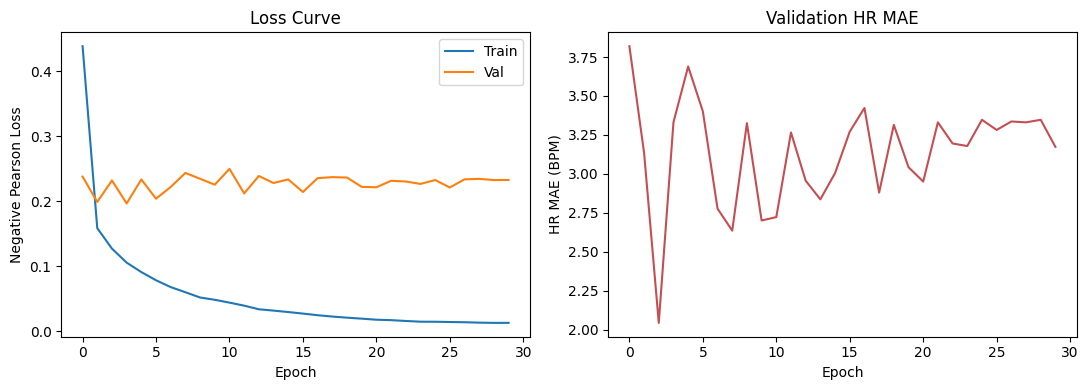

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'], label='Val')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Negative Pearson Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()

axes[1].plot(history['val_hr_mae'], color='#C44E52')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('HR MAE (BPM)')
axes[1].set_title('Validation HR MAE')

plt.tight_layout()
plt.show()

In [56]:
model.load_state_dict(torch.load(CHECKPOINT, map_location=_dev))
model.eval()

test_loss, hr_preds, hr_gts = [], [], []
with torch.no_grad():
    for frames, ppg in test_loader:
        frames, ppg = frames.to(_dev), ppg.to(_dev)
        pred = model(frames)
        test_loss.append(criterion(pred, ppg).item())
        pred_np, gt_np = pred.cpu().numpy(), ppg.cpu().numpy()
        for i in range(pred_np.shape[0]):
            hr_preds.append(signal_to_hr(pred_np[i], FPS / TEMP_RATIO))
            hr_gts.append(signal_to_hr(gt_np[i], FPS / TEMP_RATIO))

hr_preds = np.array(hr_preds)
hr_gts   = np.array(hr_gts)
errors   = hr_preds - hr_gts

metrics = {
    'test_neg_pearson_loss': float(np.mean(test_loss)),
    'hr_mae_bpm': float(np.mean(np.abs(errors))),
    'hr_rmse_bpm': float(np.sqrt(np.mean(errors**2))),
    'hr_pearson_r': float(np.corrcoef(hr_preds, hr_gts)[0, 1]) if len(hr_preds) > 1 else float('nan'),
}
metrics

{'test_neg_pearson_loss': 0.2391845617029402,
 'hr_mae_bpm': 1.519775390625,
 'hr_rmse_bpm': 2.363692318814198,
 'hr_pearson_r': 0.9550650870489747}

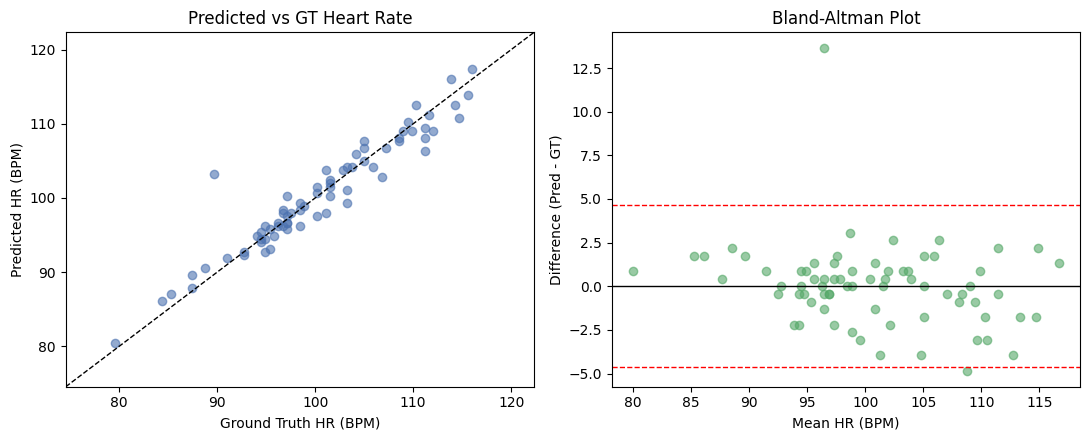

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

lims = [min(hr_gts.min(), hr_preds.min()) - 5, max(hr_gts.max(), hr_preds.max()) + 5]
axes[0].scatter(hr_gts, hr_preds, alpha=0.6, color='#4C72B0')
axes[0].plot(lims, lims, 'k--', linewidth=1)
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel('Ground Truth HR (BPM)')
axes[0].set_ylabel('Predicted HR (BPM)')
axes[0].set_title('Predicted vs GT Heart Rate')

mean_hr = (hr_preds + hr_gts) / 2
diff_hr = hr_preds - hr_gts
md_ = diff_hr.mean()
sd_ = diff_hr.std()
axes[1].scatter(mean_hr, diff_hr, alpha=0.6, color='#55A868')
axes[1].axhline(md_, color='black', linestyle='-', linewidth=1)
axes[1].axhline(md_ + 1.96*sd_, color='red', linestyle='--', linewidth=1)
axes[1].axhline(md_ - 1.96*sd_, color='red', linestyle='--', linewidth=1)
axes[1].set_xlabel('Mean HR (BPM)')
axes[1].set_ylabel('Difference (Pred - GT)')
axes[1].set_title('Bland-Altman Plot')

plt.tight_layout()
plt.show()

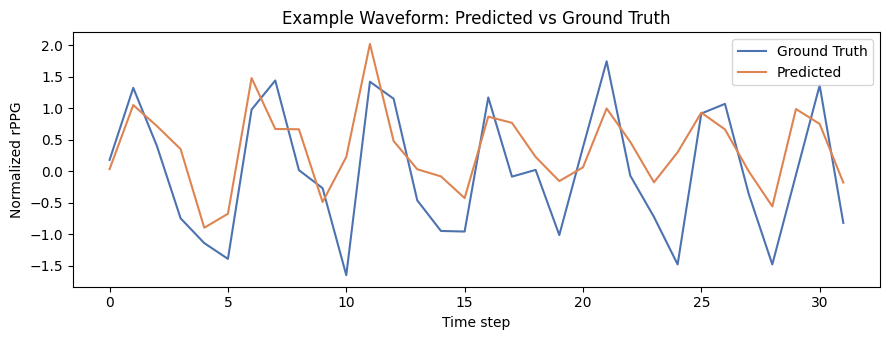

In [58]:
frames_ex, ppg_ex = next(iter(test_loader))
with torch.no_grad():
    pred_ex = model(frames_ex.to(_dev)).cpu().numpy()
gt_ex = ppg_ex.numpy()

plt.figure(figsize=(9, 3.5))
plt.plot(gt_ex[0], label='Ground Truth', color='#4C72B0')
plt.plot(pred_ex[0], label='Predicted', color='#DD8452')
plt.xlabel('Time step')
plt.ylabel('Normalized rPPG')
plt.title('Example Waveform: Predicted vs Ground Truth')
plt.legend()
plt.tight_layout()
plt.show()

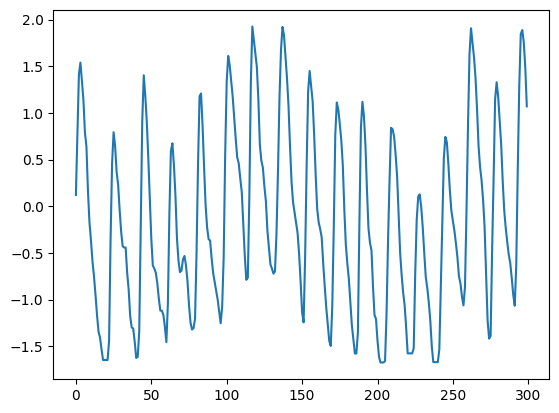

[ 0.12028675  0.7736066   1.4119226   1.5395677   1.3443377   1.134059
  0.7886104   0.638437    0.16214427 -0.17258076]


In [59]:
d = np.load(os.path.join(CACHE_DIR, sorted(os.listdir(CACHE_DIR))[0]))
plt.plot(d['ppg'][:300]); plt.show()
print(d['ppg'][:10])

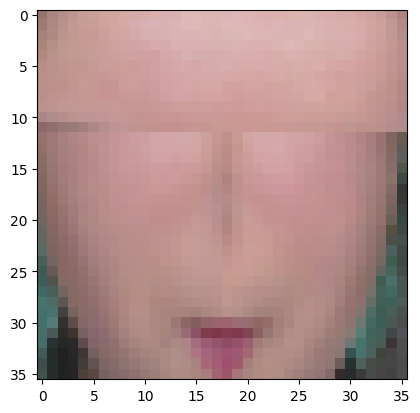

In [34]:
plt.imshow(d['frames'][0]); plt.show()

In [46]:
bad = np.argsort(-np.abs(errors))[:5]
print(errors[bad], hr_gts[bad], hr_preds[bad])

[ 51.85546875  36.03515625 -18.89648438  14.0625      -4.39453125] [100.1953125  111.18164062 110.30273438  89.6484375  114.2578125 ] [152.05078125 147.21679688  91.40625    103.7109375  109.86328125]
